In [4]:
# ============================================================
# CELL 1 — Imports and setup
# ============================================================
# Install tensorflow if it is missing from the environment
import sys
try:
    import tensorflow as tf
except ImportError:
    print("TensorFlow not found. Installing...")
    !{sys.executable} -m pip install -q tensorflow
    import tensorflow as tf

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve2d
from tensorflow import keras
from tensorflow.keras import layers
from google.colab import files
from PIL import Image
import io

np.set_printoptions(precision=3, suppress=True)

print("TensorFlow version:", tf.__version__)
print("Ready.")

TensorFlow not found. Installing...


/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:90: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


TensorFlow version: 2.21.0
Ready.


## Part I — Select and prepare the input image

The manual asks for a clear grayscale or RGB image containing distinct geometric edges, textures, and contrast gradients.

Saving images (9).jfif to images (9).jfif
Image: images (9).jfif
Image size used for filtering: (287, 512)


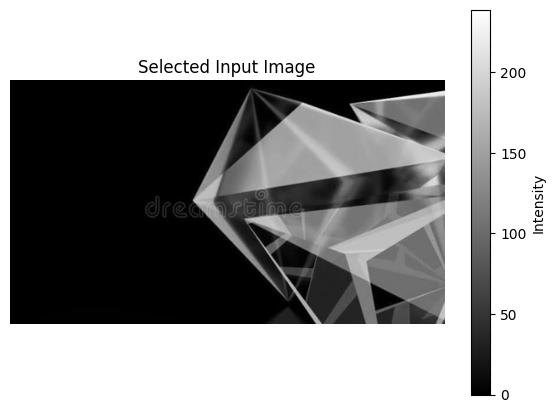

In [5]:
# ============================================================
# CELL 2 — Upload image
# ============================================================
uploaded = files.upload()

if not uploaded:
    raise ValueError("No image was uploaded.")

filename = next(iter(uploaded))
img = Image.open(io.BytesIO(uploaded[filename])).convert("RGB")

# Convert to grayscale for the custom spatial-filter visualization.
gray = np.asarray(img.convert("L"), dtype=np.float32)

# Keep the image manageable for Colab and visualization.
MAX_SIZE = 512
if max(gray.shape) > MAX_SIZE:
    scale = MAX_SIZE / max(gray.shape)
    new_size = (int(gray.shape[1] * scale), int(gray.shape[0] * scale))
    gray = np.asarray(Image.fromarray(gray.astype(np.uint8)).resize(new_size), dtype=np.float32)

print("Image:", filename)
print("Image size used for filtering:", gray.shape)

plt.figure(figsize=(7,5))
plt.imshow(gray, cmap="gray")
plt.title("Selected Input Image")
plt.axis("off")
plt.colorbar(label="Intensity")
plt.show()


## Five required 3×3 kernels

The five filters required by the manual are:
- Horizontal edge detector
- Vertical edge detector
- Sharpen
- Box/Gaussian blur
- Emboss

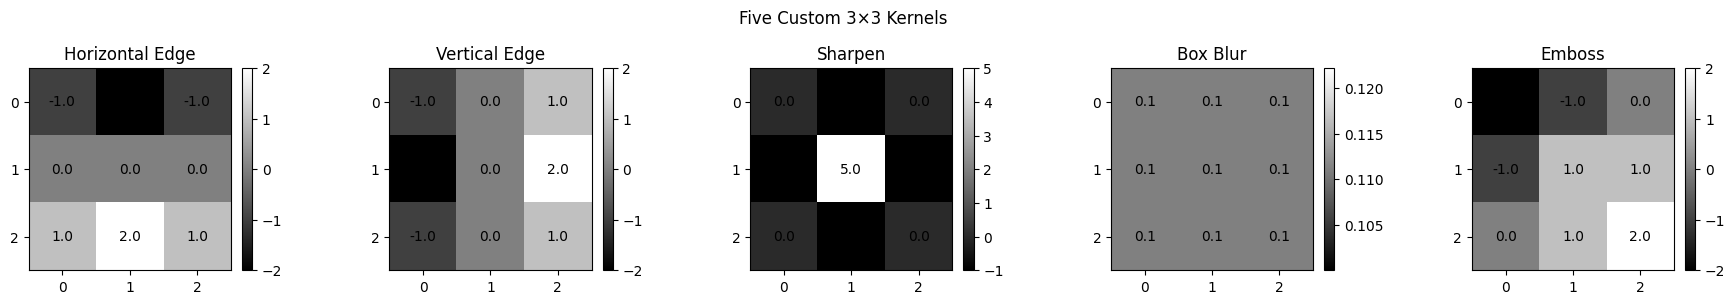

In [6]:
# ============================================================
# CELL 3 — Define the five required 3×3 kernels
# ============================================================

kernels = {
    "Horizontal Edge": np.array([
        [-1, -2, -1],
        [ 0,  0,  0],
        [ 1,  2,  1]
    ], dtype=np.float32),

    "Vertical Edge": np.array([
        [-1,  0,  1],
        [-2,  0,  2],
        [-1,  0,  1]
    ], dtype=np.float32),

    "Sharpen": np.array([
        [ 0, -1,  0],
        [-1,  5, -1],
        [ 0, -1,  0]
    ], dtype=np.float32),

    # Box blur is explicitly allowed by the manual's
    # "Box/Gaussian Blur Kernel" requirement.
    "Box Blur": np.ones((3, 3), dtype=np.float32) / 9.0,

    "Emboss": np.array([
        [-2, -1,  0],
        [-1,  1,  1],
        [ 0,  1,  2]
    ], dtype=np.float32)
}

fig, axes = plt.subplots(1, 5, figsize=(18, 3))
for ax, (name, kernel) in zip(axes, kernels.items()):
    im = ax.imshow(kernel, cmap="gray")
    ax.set_title(name)
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    for r in range(3):
        for c in range(3):
            ax.text(c, r, f"{kernel[r,c]:.1f}", ha="center", va="center")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle("Five Custom 3×3 Kernels")
plt.tight_layout()
plt.show()


## Sequential pipeline

For each filter:
- **Stage A:** Raw convolution output
- **Stage B:** ReLU = `max(0, x)`
- **Stage C:** 2×2 Max Pooling, stride 2, applied to Stage B
- **Stage D:** 2×2 Average Pooling, stride 2, applied to Stage B

Both pooling operations start from the same Post-ReLU feature map, as required by the manual.

In [7]:
# ============================================================
# CELL 4 — Run all five filters through all four stages
# ============================================================

def relu(x):
    return np.maximum(0, x)

def pool_2x2(x, mode="max"):
    h, w = x.shape
    h2 = h - (h % 2)
    w2 = w - (w % 2)
    x = x[:h2, :w2]

    # Non-overlapping 2x2 pooling, stride 2.
    blocks = x.reshape(h2 // 2, 2, w2 // 2, 2)

    if mode == "max":
        return blocks.max(axis=(1, 3))
    elif mode == "avg":
        return blocks.mean(axis=(1, 3))
    else:
        raise ValueError("mode must be 'max' or 'avg'")

results = {}

for name, kernel in kernels.items():
    raw = convolve2d(gray, kernel, mode="same", boundary="symm")
    relu_map = relu(raw)
    max_pool = pool_2x2(relu_map, mode="max")
    avg_pool = pool_2x2(relu_map, mode="avg")

    results[name] = {
        "A_raw": raw,
        "B_relu": relu_map,
        "C_maxpool": max_pool,
        "D_avgpool": avg_pool
    }

print("Pipeline completed for all 5 filters.")
for name, maps in results.items():
    print(f"{name:18s}:", {k: v.shape for k, v in maps.items()})


Pipeline completed for all 5 filters.
Horizontal Edge   : {'A_raw': (287, 512), 'B_relu': (287, 512), 'C_maxpool': (143, 256), 'D_avgpool': (143, 256)}
Vertical Edge     : {'A_raw': (287, 512), 'B_relu': (287, 512), 'C_maxpool': (143, 256), 'D_avgpool': (143, 256)}
Sharpen           : {'A_raw': (287, 512), 'B_relu': (287, 512), 'C_maxpool': (143, 256), 'D_avgpool': (143, 256)}
Box Blur          : {'A_raw': (287, 512), 'B_relu': (287, 512), 'C_maxpool': (143, 256), 'D_avgpool': (143, 256)}
Emboss            : {'A_raw': (287, 512), 'B_relu': (287, 512), 'C_maxpool': (143, 256), 'D_avgpool': (143, 256)}


## Required 5 × 4 visualization grid

This produces the main evidence figure required by the lab manual: **5 rows × 4 columns**, with titles and colorbars/intensity scales.

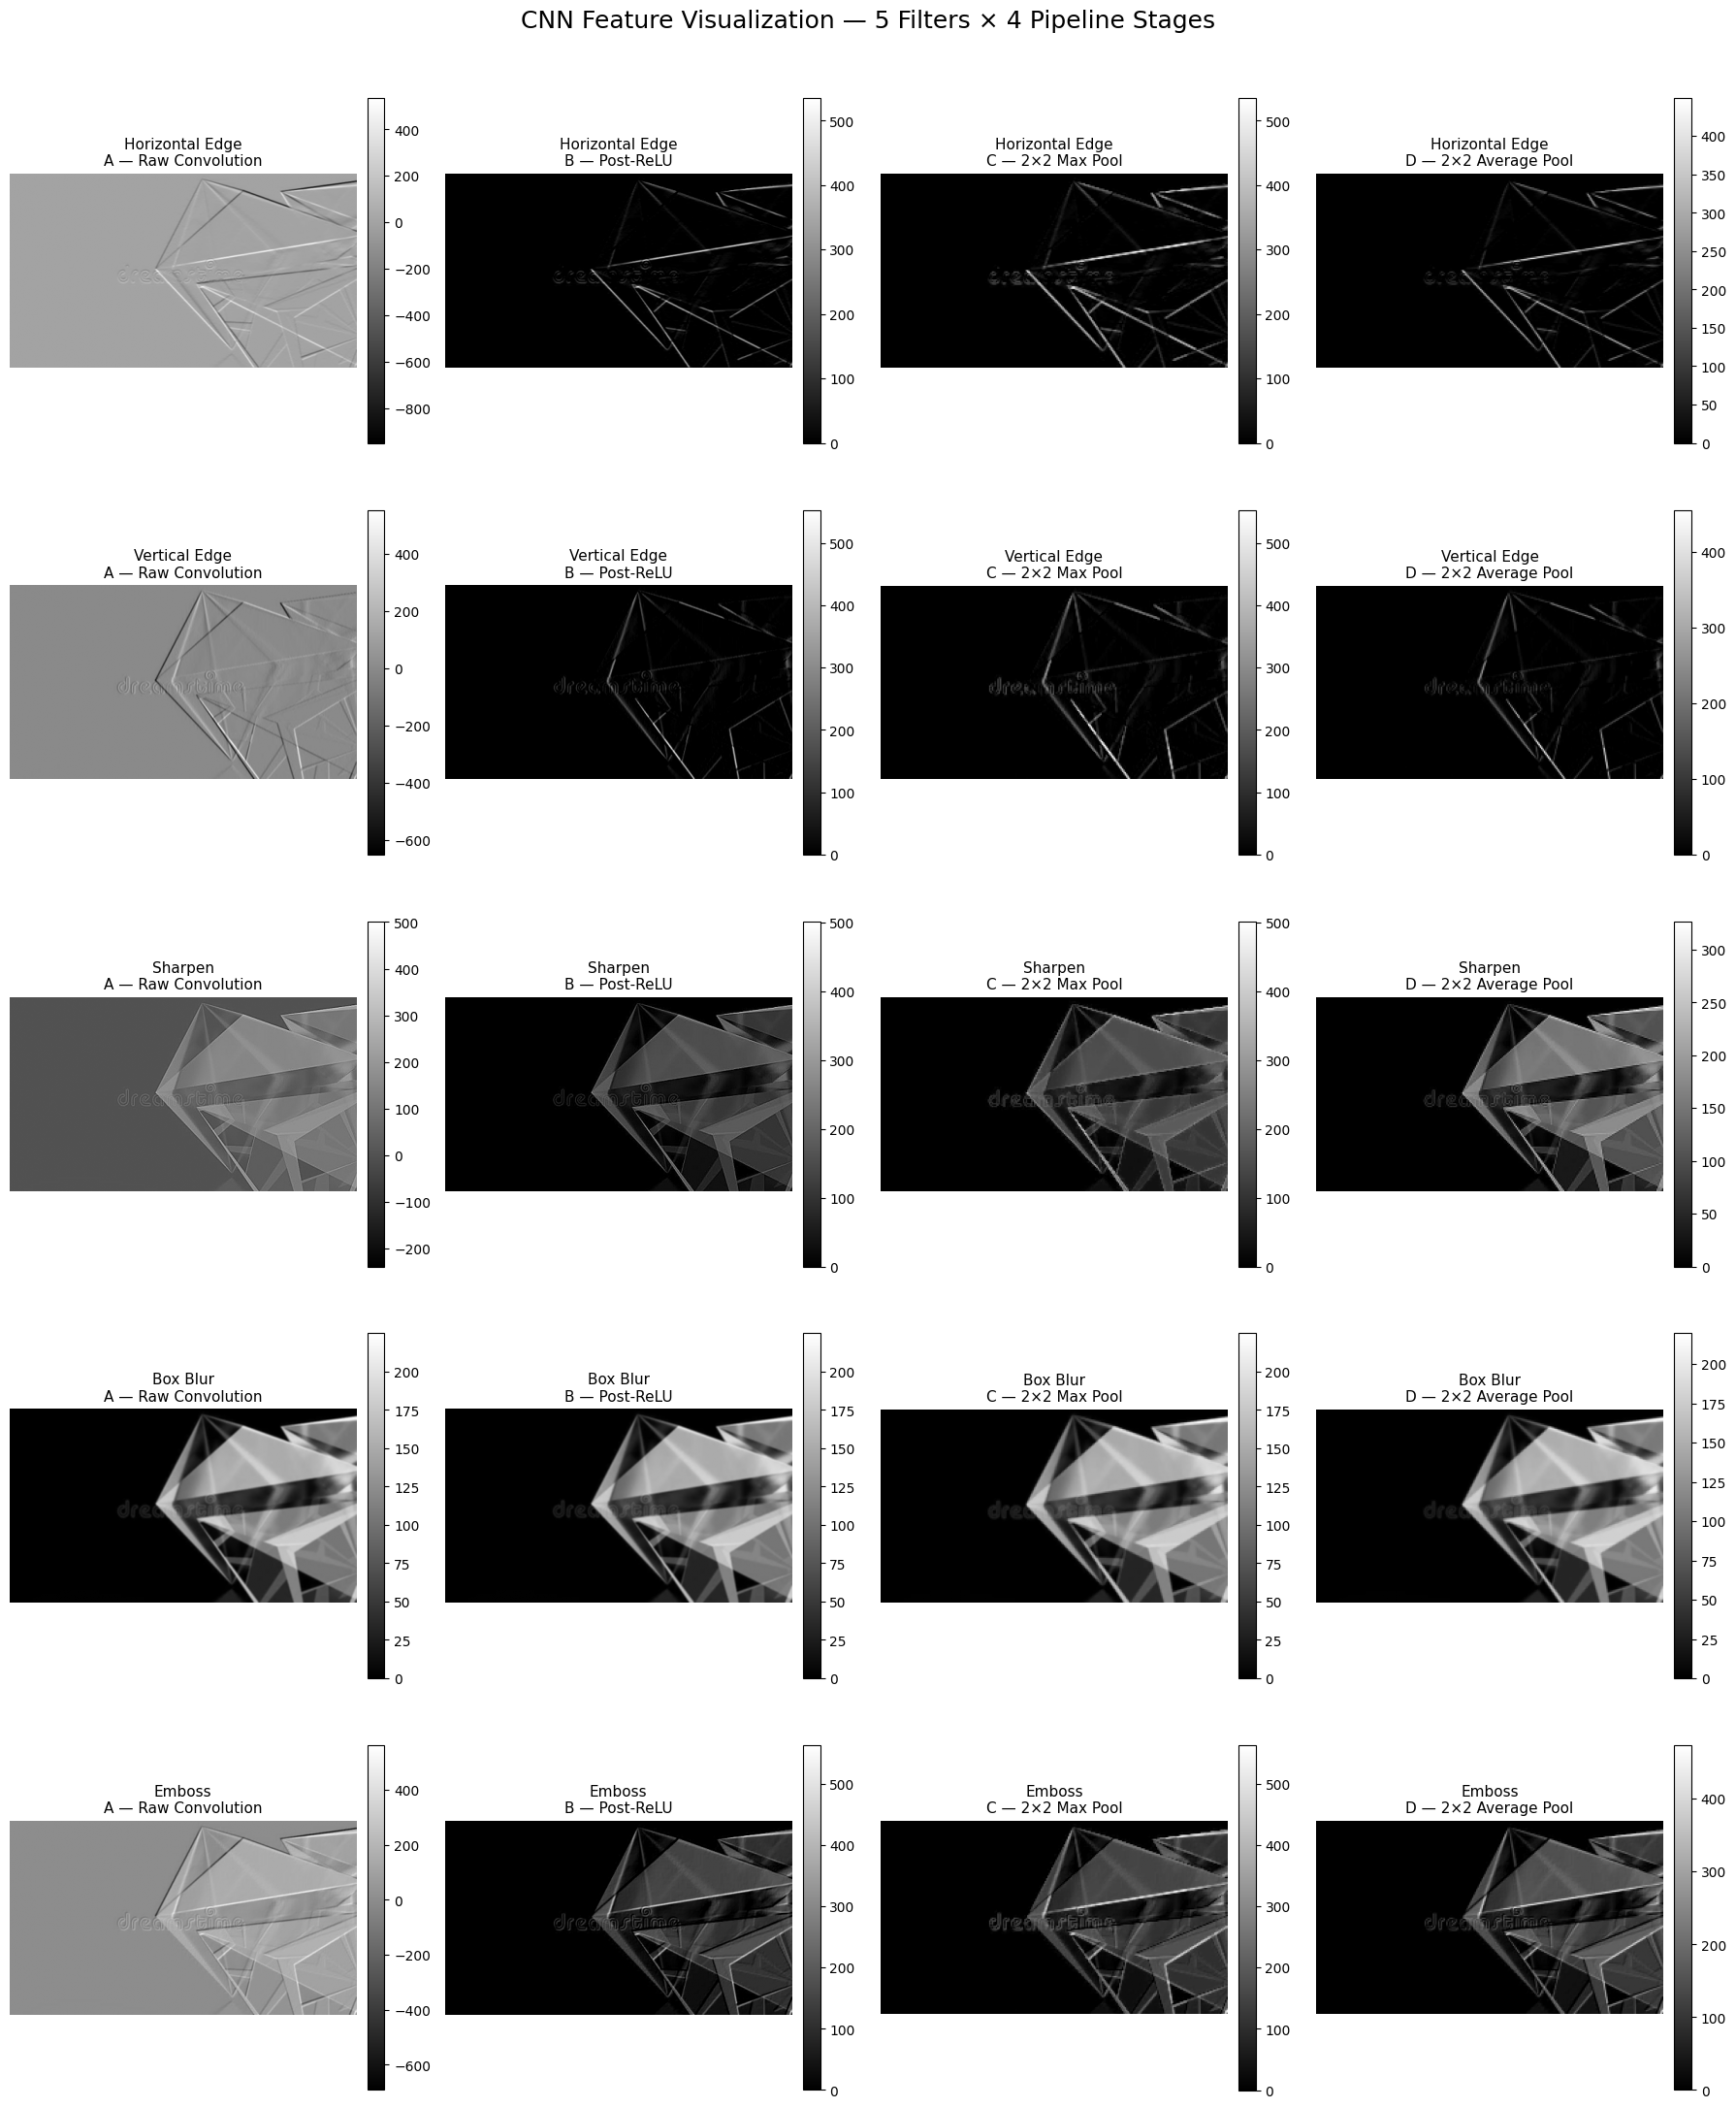

Saved: CNN_5x4_Visualization_Grid.png


In [8]:
# ============================================================
# CELL 5 — Required 5 × 4 visualization grid
# ============================================================

stage_names = [
    ("A — Raw Convolution", "A_raw"),
    ("B — Post-ReLU", "B_relu"),
    ("C — 2×2 Max Pool", "C_maxpool"),
    ("D — 2×2 Average Pool", "D_avgpool")
]

filter_names = list(kernels.keys())

fig, axes = plt.subplots(5, 4, figsize=(18, 22))

for row, filter_name in enumerate(filter_names):
    for col, (title, key) in enumerate(stage_names):
        ax = axes[row, col]
        data = results[filter_name][key]

        im = ax.imshow(data, cmap="gray")
        ax.set_title(f"{filter_name}\n{title}", fontsize=11)
        ax.axis("off")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)

plt.suptitle("CNN Feature Visualization — 5 Filters × 4 Pipeline Stages",
             fontsize=18, y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.99])

# Save the required figure for the report.
plt.savefig("CNN_5x4_Visualization_Grid.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved: CNN_5x4_Visualization_Grid.png")


## Useful numerical evidence from Part I

These values help you write the critical-analysis answers using **your own generated feature maps** rather than generic statements.

In [9]:
# ============================================================
# CELL 6 — Evidence/statistics for Questions 1 and 2
# ============================================================

print("=" * 75)
print("PART I NUMERICAL EVIDENCE")
print("=" * 75)

for name in ["Horizontal Edge", "Vertical Edge", "Sharpen", "Box Blur", "Emboss"]:
    raw = results[name]["A_raw"]
    relu_map = results[name]["B_relu"]
    max_map = results[name]["C_maxpool"]
    avg_map = results[name]["D_avgpool"]

    negative_pct = np.mean(raw < 0) * 100
    zero_after_relu_pct = np.mean(relu_map == 0) * 100

    print(f"\n{name}")
    print(f"  Raw min/max              : {raw.min():.3f} / {raw.max():.3f}")
    print(f"  Negative raw pixels     : {negative_pct:.2f}%")
    print(f"  Zero pixels after ReLU  : {zero_after_relu_pct:.2f}%")
    print(f"  Max-pool mean/max       : {max_map.mean():.3f} / {max_map.max():.3f}")
    print(f"  Avg-pool mean/max       : {avg_map.mean():.3f} / {avg_map.max():.3f}")

# Compare Max vs Average pooling for edge/sharpen maps.
print("\n" + "=" * 75)
print("MAX POOLING VS AVERAGE POOLING — HIGH-RESPONSE COMPARISON")
print("=" * 75)

for name in ["Horizontal Edge", "Vertical Edge", "Sharpen"]:
    max_map = results[name]["C_maxpool"]
    avg_map = results[name]["D_avgpool"]

    print(f"\n{name}")
    print(f"  Max-pool maximum   = {max_map.max():.3f}")
    print(f"  Avg-pool maximum   = {avg_map.max():.3f}")
    print(f"  Max-pool mean      = {max_map.mean():.3f}")
    print(f"  Avg-pool mean      = {avg_map.mean():.3f}")
    print(f"  Max/Avg max ratio  = {max_map.max() / (avg_map.max() + 1e-8):.3f}")


PART I NUMERICAL EVIDENCE

Horizontal Edge
  Raw min/max              : -950.000 / 535.000
  Negative raw pixels     : 20.98%
  Zero pixels after ReLU  : 79.57%
  Max-pool mean/max       : 14.381 / 535.000
  Avg-pool mean/max       : 8.749 / 449.500

Vertical Edge
  Raw min/max              : -651.000 / 553.000
  Negative raw pixels     : 22.20%
  Zero pixels after ReLU  : 80.26%
  Max-pool mean/max       : 10.535 / 553.000
  Avg-pool mean/max       : 6.526 / 455.250

Sharpen
  Raw min/max              : -238.000 / 501.000
  Negative raw pixels     : 3.57%
  Zero pixels after ReLU  : 52.90%
  Max-pool mean/max       : 53.227 / 501.000
  Avg-pool mean/max       : 46.781 / 326.500

Box Blur
  Raw min/max              : 0.000 / 224.889
  Negative raw pixels     : 0.00%
  Zero pixels after ReLU  : 48.86%
  Max-pool mean/max       : 47.917 / 224.889
  Avg-pool mean/max       : 46.023 / 219.444

Emboss
  Raw min/max              : -692.000 / 563.000
  Negative raw pixels     : 6.04%
  Zero p

# Part II — Architectural Comparison & Parameter Audit

The manual specifies:

### Model A — Standard
- Input: 32×32×3
- Conv1: 5 filters, 3×3
- Conv2: 10 filters, 3×3
- 2×2 Max Pooling, stride 2
- Global Average Pooling
- Dense: 10 classes

### Model B — Large Kernel
- Input: 32×32×3
- Conv1: 5 filters, 5×5
- Conv2: 10 filters, 5×5
- 2×2 Average Pooling, stride 2
- Global Average Pooling
- Dense: 10 classes

The manual asks for exact trainable parameter counts and a framework model-summary verification.

In [10]:
# ============================================================
# CELL 7 — Build Model A and Model B
# ============================================================

def build_model_a():
    inputs = keras.Input(shape=(32, 32, 3), name="Input_32x32x3")

    x = layers.Conv2D(5, (3, 3), padding="same", activation=None, name="Conv1_3x3")(inputs)
    x = layers.Conv2D(10, (3, 3), padding="same", activation=None, name="Conv2_3x3")(x)
    x = layers.MaxPooling2D(pool_size=(2, 2), strides=2, name="MaxPool_2x2")(x)
    x = layers.GlobalAveragePooling2D(name="GlobalAveragePooling")(x)
    outputs = layers.Dense(10, name="Dense_10")(x)

    return keras.Model(inputs, outputs, name="Model_A_Standard")


def build_model_b():
    inputs = keras.Input(shape=(32, 32, 3), name="Input_32x32x3")

    x = layers.Conv2D(5, (5, 5), padding="same", activation=None, name="Conv1_5x5")(inputs)
    x = layers.Conv2D(10, (5, 5), padding="same", activation=None, name="Conv2_5x5")(x)
    x = layers.AveragePooling2D(pool_size=(2, 2), strides=2, name="AvgPool_2x2")(x)
    x = layers.GlobalAveragePooling2D(name="GlobalAveragePooling")(x)
    outputs = layers.Dense(10, name="Dense_10")(x)

    return keras.Model(inputs, outputs, name="Model_B_Large_Kernel")


model_a = build_model_a()
model_b = build_model_b()

print("MODEL A")
model_a.summary()

print("\nMODEL B")
model_b.summary()


MODEL A


Model: "Model_A_Standard"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_32x32x3 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv1_3x3 (Conv2D)              │ (None, 32, 32, 5)      │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv2_3x3 (Conv2D)              │ (None, 32, 32, 10)     │           460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPool_2x2 (MaxPooling2D)      │ (None, 16, 16, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ GlobalAveragePooling            │ (None, 10)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_10 (Dense)                │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 710 (2.77 KB)

 Trainable params: 710 (2.77 KB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_32x32x3 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv1_5x5 (Conv2D)              │ (None, 32, 32, 5)      │           380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv2_5x5 (Conv2D)              │ (None, 32, 32, 10)     │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ AvgPool_2x2 (AveragePooling2D)  │ (None, 16, 16, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ GlobalAveragePooling            │ (None, 10)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_10 (Dense)                │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,750 (6.84 KB)

 Trainable params: 1,750 (6.84 KB)

 Non-trainable params: 0 (0.00 B)

## Manual parameter audit

For a convolution layer, the lab manual gives:

\[
(K_h 	imes K_w 	imes C_{in} + 1)	imes C_{out}
\]

The `+1` accounts for one bias parameter per output filter.

For the Dense layer:

\[
(C_{in}+1)	imes C_{out}
\]

The code below prints the exact hand-calculation steps and compares them with Keras.

In [11]:
# ============================================================
# CELL 8 — Manual parameter calculations
# ============================================================

def conv_params(k, cin, cout):
    return (k * k * cin + 1) * cout

def dense_params(cin, cout):
    return (cin + 1) * cout

def audit_model(model_name, k):
    # Input is RGB: Cin=3
    conv1 = conv_params(k, 3, 5)

    # Conv2 receives 5 channels from Conv1
    conv2 = conv_params(k, 5, 10)

    # Global Average Pooling after Conv2 leaves 10 values.
    dense = dense_params(10, 10)

    total = conv1 + conv2 + dense

    print(f"\n{'='*70}")
    print(f"{model_name}")
    print(f"{'='*70}")

    print(f"Conv1: ({k}×{k}×3 + 1) × 5")
    print(f"      = ({k*k*3} + 1) × 5")
    print(f"      = {conv1:,} parameters")

    print(f"\nConv2: ({k}×{k}×5 + 1) × 10")
    print(f"      = ({k*k*5} + 1) × 10")
    print(f"      = {conv2:,} parameters")

    print("\nGlobal Average Pooling: 10 channels → 10 values")

    print("\nDense: (10 + 1) × 10")
    print(f"      = {dense:,} parameters")

    print(f"\nTOTAL TRAINABLE PARAMETERS = {total:,}")

    return {
        "Conv1": conv1,
        "Conv2": conv2,
        "Dense": dense,
        "Total": total
    }

audit_a = audit_model("MODEL A — 3×3 + MAX POOLING", 3)
audit_b = audit_model("MODEL B — 5×5 + AVERAGE POOLING", 5)

print("\n" + "="*70)
print("MANUAL COMPARISON")
print("="*70)

increase = (audit_b["Total"] - audit_a["Total"]) / audit_a["Total"] * 100
print(f"Model A total parameters: {audit_a['Total']:,}")
print(f"Model B total parameters: {audit_b['Total']:,}")
print(f"Percentage increase: {increase:.2f}%")



MODEL A — 3×3 + MAX POOLING
Conv1: (3×3×3 + 1) × 5
      = (27 + 1) × 5
      = 140 parameters

Conv2: (3×3×5 + 1) × 10
      = (45 + 1) × 10
      = 460 parameters

Global Average Pooling: 10 channels → 10 values

Dense: (10 + 1) × 10
      = 110 parameters

TOTAL TRAINABLE PARAMETERS = 710

MODEL B — 5×5 + AVERAGE POOLING
Conv1: (5×5×3 + 1) × 5
      = (75 + 1) × 5
      = 380 parameters

Conv2: (5×5×5 + 1) × 10
      = (125 + 1) × 10
      = 1,260 parameters

Global Average Pooling: 10 channels → 10 values

Dense: (10 + 1) × 10
      = 110 parameters

TOTAL TRAINABLE PARAMETERS = 1,750

MANUAL COMPARISON
Model A total parameters: 710
Model B total parameters: 1,750
Percentage increase: 146.48%


## Receptive-field comparison

The lab asks how many stacked 3×3 convolutions are needed to obtain the same spatial receptive field as one 5×5 convolution.

For stride 1 and no dilation:
- one 3×3 layer → 3×3 receptive field
- two stacked 3×3 layers → 5×5 receptive field

The next cell calculates the parameter comparison for the same 5→10-channel setup.

In [12]:
# ============================================================
# CELL 9 — Receptive field and parameter saving
# ============================================================

# One 5x5 layer from 5 input channels to 10 output channels:
one_5x5 = conv_params(5, 5, 10)

# Two 3x3 layers: first 5->5, second 5->10.
stacked_3x3 = conv_params(3, 5, 5) + conv_params(3, 5, 10)

saving = one_5x5 - stacked_3x3
saving_pct = saving / one_5x5 * 100

print("To match a 5×5 receptive field:")
print("Required stacked 3×3 layers: 2")
print()
print(f"One 5×5 conv (5→10): {one_5x5:,} parameters")
print(f"Two 3×3 convs (5→5→10): {stacked_3x3:,} parameters")
print(f"Parameter saving: {saving:,}")
print(f"Saving percentage relative to one 5×5 conv: {saving_pct:.2f}%")


To match a 5×5 receptive field:
Required stacked 3×3 layers: 2

One 5×5 conv (5→10): 1,260 parameters
Two 3×3 convs (5→5→10): 690 parameters
Parameter saving: 570
Saving percentage relative to one 5×5 conv: 45.24%
